# Figure partitioning reanalysis uncertainty between impact model fitting and BCDS process

In [1]:
import xarray as xr
import numpy as np
import pandas as pd
import geopandas as gpd
from matplotlib import pyplot as plt
from cartopy import crs as ccrs
import cmocean
import seaborn as sns
import warnings

import os
import glob
import re

from funcs_support import get_filepaths,get_params,utility_save,utility_print
dir_list = get_params()
dir_list['aux_bigmem'] = '/glade/derecho/scratch/schwarzwald/impact_uncertainty/aux/'

In [2]:
from distributed import Client

# Start dask client 
# (playing around with workers, threads for efficiency)
client = Client(n_workers=6,
    threads_per_worker=3,
    processes=True,
    memory_limit="8GB")
display(client)

/glade/u/home/schwarzwald/.conda/envs/impact_uncert/lib/python3.14/site-packages/distributed/node.py:188: UserWarning: Port 8787 is already in use.
Perhaps you already have a cluster running?
Hosting the HTTP server on port 40145 instead
  warnings.warn(


Connection method: Cluster object,Cluster type: distributed.LocalCluster
Dashboard: https://jupyterhub.hpc.ucar.edu/stable/user/schwarzwald/bcd_me_proc/proxy/40145/status,
Dashboard: https://jupyterhub.hpc.ucar.edu/stable/user/schwarzwald/bcd_me_proc/proxy/40145/status,Workers: 6
Total threads: 18,Total memory: 44.70 GiB
Status: running,Using processes: True
Comm: tcp://127.0.0.1:35399,Workers: 0
Dashboard: https://jupyterhub.hpc.ucar.edu/stable/user/schwarzwald/bcd_me_proc/proxy/40145/status,Total threads: 0
Started: Just now,Total memory: 0 B
Comm: tcp://127.0.0.1:42415,Total threads: 3
Dashboard: https://jupyterhub.hpc.ucar.edu/stable/user/schwarzwald/bcd_me_proc/proxy/35991/status,Memory: 7.45 GiB
Nanny: tcp://127.0.0.1:44459,


In [3]:
params_proc = {'mortality':{'varname':'tassumpoly','geo_typ':'impact-regions','shp_fn':'impact-region','popwght':False},
               'gdppc':{'varname':'tassumpoly','geo_typ':'adm1','shp_fn':'country-fixed','popwght':True},
               'payroll':{'varname':'days90plus','geo_typ':'adm2-us','shp_fn':'UScounties','popwght':True}}



In [6]:
def load_impacts(proc,uncert_typ,return_maxgwl = False,return_crossfits=False):
    '''
    NOTE: MAX_GWL IS HARDCODED HERE
    '''
    
    # Load impacts projections
    if return_crossfits:
        fns = np.sort(glob.glob(f'{dir_list['proc']}impact_projs/{proc}/d{proc}-cross*.zarr'))
    else:
        fns = np.sort(glob.glob(f'{dir_list['proc']}impact_projs/{proc}/d{proc}_*.zarr'))
    def load_impact(fn):
        ds_tmp = xr.open_zarr(fn,consolidated=False)
        ds_tmp = ds_tmp.set_coords('locid') # Should be coordinate, instead of concatenated variable
        ds_tmp = ds_tmp.assign_coords({'model':(('idv'),[re.split(r'\_',re.split(r'\/',fn)[-1])[2]]*ds_tmp.sizes['idv'])})
    
        ds_tmp['exprun'] = ds_tmp['experiment']+ds_tmp['run']
        ds_tmp = ds_tmp.reset_index('idv')
        ds_tmp = ds_tmp.set_index(idv = ['model','exprun'])
        return ds_tmp
    
    with warnings.catch_warnings():
        # Silence zarr warnings related to the /.done flags used
        warnings.filterwarnings('ignore')
        dss = xr.concat([load_impact(fn) for fn in fns],
                    dim='idv',join='outer')
    
    dss = dss.set_index({'poly_idx':'locid'}).rename({'poly_idx':'locid'})

    if return_maxgwl:
        return dss.maxgwl
    
    # Figure out how many BCD-ME members reach a given GWL
    gwl_counter = dss.maxgwl.load().reset_index('idv').groupby(['model','maxgwl']).count()
    gwl_counter = gwl_counter.sel(maxgwl = gwl_counter.maxgwl.values[::-1]).cumsum('maxgwl')
    #print(gwl_counter)
    
    dss_tmp = dss
    
    if 'noMERRA2' in uncert_typ:
        dss_tmp = dss_tmp.sel(proj_base = [pb for pb in dss_tmp.proj_base.values if pb != 'MERRA2'])
    
    if re.search(r'[0-9].*runs[0-9].*mods',uncert_typ):
        max_gwl = 3
        nruns = int(re.split('runs',uncert_typ)[0])
        
        gwlmods = gwl_counter.sel(maxgwl=max_gwl)
        proc_mods = gwlmods.isel(model = gwlmods>=nruns).model.values
        
        dss_tmp = dss_tmp.isel(idv = dss.maxgwl>=max_gwl).groupby('model').map(lambda x: x.isel(idv=slice(0, nruns)))
        dss_tmp = dss_tmp.isel(idv=[m in proc_mods for m in dss_tmp.model.values]).chunk({'idv':-1})

    for v in ['experiment','run']:
        dss_tmp[v] = dss_tmp[v].astype(object)
    dss_tmp = dss_tmp.unstack('idv')['d'+proc]
    #dss_tmp = dss_tmp.chunk({'model':-1,'exprun':-1})

    return dss_tmp

In [7]:
obsuncs_all = {}
overwrite = True
for proc in params_proc:
    tmp_fn1 = f'{dir_list['aux_bigmem']}crossfit_{proc}_rechk_tmp1.zarr'
    tmp_fn2 = f'{dir_list['aux_bigmem']}crossfit_{proc}_rechk_tmp2.zarr'
    if overwrite or (not os.path.exists(tmp_fn2)):
        dss = load_impacts(proc,'allruns',return_crossfits=True)
        dss = dss.chunk({'gwl':1,'fit_mod':-1,'proj_base':-1,'locid':5000})
        # Save rechunked as temporary file
        
        utility_save(dss,tmp_fn1,zarr_mode='w')
        dss = xr.open_zarr(tmp_fn1)
        dss = dss.chunk({'gwl':1,'fit_mod':-1,'proj_base':-1,'locid':200,'exprun':-1,'model':-1})
        
        utility_save(dss.drop_encoding(),tmp_fn2,zarr_mode='w')
        os.system('rm -rf '+tmp_fn1)
    dss = xr.open_zarr(tmp_fn2)

    #problem_runs = [{'model':'IPSL-CM6A-LR','exprun':'ssp370r6i1p1f1'},
    #                {'model':'MPI-ESM1-2-LR','exprun':'ssp370r9i1p1f1'}]
    #for problem_run in problem_runs:
    #    dss = dss.where(~((dss.model == problem_run['model']) & 
    #            (dss.exprun == problem_run['exprun'])))
        


    obsuncs_all[proc] = xr.merge([dss.mean('fit_mod').var('proj_base').mean('exprun').mean('model').compute().rename({'d'+proc:'impmod'}),
                                    dss.var('fit_mod').mean('proj_base').mean('exprun').mean('model').compute().rename({'d'+proc:'bcds'}),
                                  dss.mean('fit_mod').mean('proj_base').var('exprun').mean('model').compute().rename({'d'+proc:'uncint'}),
                                  dss.mean('fit_mod').mean('proj_base').mean('exprun').var('model').compute().rename({'d'+proc:'uncmod'})],
                                   compat = 'no_conflicts')

/glade/derecho/scratch/schwarzwald/tmp/ipykernel_34931/2502570563.py:53: DeprecationWarning: Deleting a single level of a MultiIndex is deprecated. Previously, this deleted all levels of a MultiIndex. Please also drop the following variables: {'idv'} to avoid an error in the future.
  dss_tmp[v] = dss_tmp[v].astype(object)
/glade/u/home/schwarzwald/.conda/envs/impact_uncert/lib/python3.14/site-packages/dask/array/core.py:5189: PerformanceWarning: Increasing number of chunks by factor of 20
  result = blockwise(
/glade/u/home/schwarzwald/projects/impact_uncertainty/code/funcs_support.py:485: SerializationWarning: variable None has data in the form of a dask array with dtype=object, which means it is being loaded into memory to determine a data type that can be safely stored on disk. To avoid this, coerce this variable to a fixed-size dtype with astype() before saving it.
  ds.to_zarr(output_fn,**save_kwargs)
/glade/u/home/schwarzwald/.conda/envs/impact_uncert/lib/python3.14/site-package

/glade/derecho/scratch/schwarzwald/impact_uncertainty/aux/crossfit_mortality_rechk_tmp1.zarr saved!
/glade/derecho/scratch/schwarzwald/impact_uncertainty/aux/crossfit_mortality_rechk_tmp2.zarr removed to allow overwrite!


/glade/u/home/schwarzwald/.conda/envs/impact_uncert/lib/python3.14/site-packages/zarr/core/dtype/npy/string.py:249: UnstableSpecificationWarning: The data type (FixedLengthUTF32(length=6, endianness='little')) does not have a Zarr V3 specification. That means that the representation of arrays saved with this data type may change without warning in a future version of Zarr Python. Arrays stored with this data type may be unreadable by other Zarr libraries. Use this data type at your own risk! Check https://github.com/zarr-developers/zarr-extensions/tree/main/data-types for the status of data type specifications for Zarr V3.
  v3_unstable_dtype_warning(self)
/glade/u/home/schwarzwald/.conda/envs/impact_uncert/lib/python3.14/site-packages/zarr/core/dtype/npy/string.py:249: UnstableSpecificationWarning: The data type (FixedLengthUTF32(length=3, endianness='little')) does not have a Zarr V3 specification. That means that the representation of arrays saved with this data type may change with

/glade/derecho/scratch/schwarzwald/impact_uncertainty/aux/crossfit_mortality_rechk_tmp2.zarr saved!


/glade/u/home/schwarzwald/.conda/envs/impact_uncert/lib/python3.14/site-packages/dask/array/numpy_compat.py:61: RuntimeWarning: invalid value encountered in divide
  x = np.divide(x1, x2, out)
/glade/u/home/schwarzwald/.conda/envs/impact_uncert/lib/python3.14/site-packages/dask/array/numpy_compat.py:61: RuntimeWarning: invalid value encountered in divide
  x = np.divide(x1, x2, out)
/glade/u/home/schwarzwald/.conda/envs/impact_uncert/lib/python3.14/site-packages/dask/array/numpy_compat.py:61: RuntimeWarning: invalid value encountered in divide
  x = np.divide(x1, x2, out)
/glade/u/home/schwarzwald/.conda/envs/impact_uncert/lib/python3.14/site-packages/dask/array/numpy_compat.py:61: RuntimeWarning: invalid value encountered in divide
  x = np.divide(x1, x2, out)
/glade/u/home/schwarzwald/.conda/envs/impact_uncert/lib/python3.14/site-packages/dask/array/numpy_compat.py:61: RuntimeWarning: invalid value encountered in divide
  x = np.divide(x1, x2, out)
/glade/u/home/schwarzwald/.conda/en

...

/glade/derecho/scratch/schwarzwald/impact_uncertainty/aux/crossfit_gdppc_rechk_tmp2.zarr saved!


/glade/derecho/scratch/schwarzwald/tmp/ipykernel_34931/2502570563.py:53: DeprecationWarning: Deleting a single level of a MultiIndex is deprecated. Previously, this deleted all levels of a MultiIndex. Please also drop the following variables: {'idv'} to avoid an error in the future.
  dss_tmp[v] = dss_tmp[v].astype(object)
/glade/u/home/schwarzwald/projects/impact_uncertainty/code/funcs_support.py:485: SerializationWarning: variable None has data in the form of a dask array with dtype=object, which means it is being loaded into memory to determine a data type that can be safely stored on disk. To avoid this, coerce this variable to a fixed-size dtype with astype() before saving it.
  ds.to_zarr(output_fn,**save_kwargs)
/glade/u/home/schwarzwald/.conda/envs/impact_uncert/lib/python3.14/site-packages/zarr/core/dtype/npy/string.py:249: UnstableSpecificationWarning: The data type (FixedLengthUTF32(length=6, endianness='little')) does not have a Zarr V3 specification. That means that the re

/glade/derecho/scratch/schwarzwald/impact_uncertainty/aux/crossfit_payroll_rechk_tmp1.zarr saved!
/glade/derecho/scratch/schwarzwald/impact_uncertainty/aux/crossfit_payroll_rechk_tmp2.zarr removed to allow overwrite!


/glade/u/home/schwarzwald/.conda/envs/impact_uncert/lib/python3.14/site-packages/zarr/core/dtype/npy/string.py:249: UnstableSpecificationWarning: The data type (FixedLengthUTF32(length=9, endianness='little')) does not have a Zarr V3 specification. That means that the representation of arrays saved with this data type may change without warning in a future version of Zarr Python. Arrays stored with this data type may be unreadable by other Zarr libraries. Use this data type at your own risk! Check https://github.com/zarr-developers/zarr-extensions/tree/main/data-types for the status of data type specifications for Zarr V3.
  v3_unstable_dtype_warning(self)
/glade/u/home/schwarzwald/.conda/envs/impact_uncert/lib/python3.14/site-packages/zarr/core/dtype/npy/string.py:249: UnstableSpecificationWarning: The data type (FixedLengthUTF32(length=6, endianness='little')) does not have a Zarr V3 specification. That means that the representation of arrays saved with this data type may change with

/glade/derecho/scratch/schwarzwald/impact_uncertainty/aux/crossfit_payroll_rechk_tmp2.zarr saved!


/glade/u/home/schwarzwald/.conda/envs/impact_uncert/lib/python3.14/site-packages/pyogrio/raw.py:200: RuntimeWarning: /glade/u/home/schwarzwald/projects/impact_uncertainty/aux_data/geo_data/impact-region.shp contains polygon(s) with rings with invalid winding order. Autocorrecting them, but that shapefile should be corrected using ogr2ogr for example.
  return ogr_read(


/glade/u/home/schwarzwald/projects/impact_uncertainty/figures/Figure4.pdf saved!
/glade/u/home/schwarzwald/projects/impact_uncertainty/figures/Figure4.png saved!


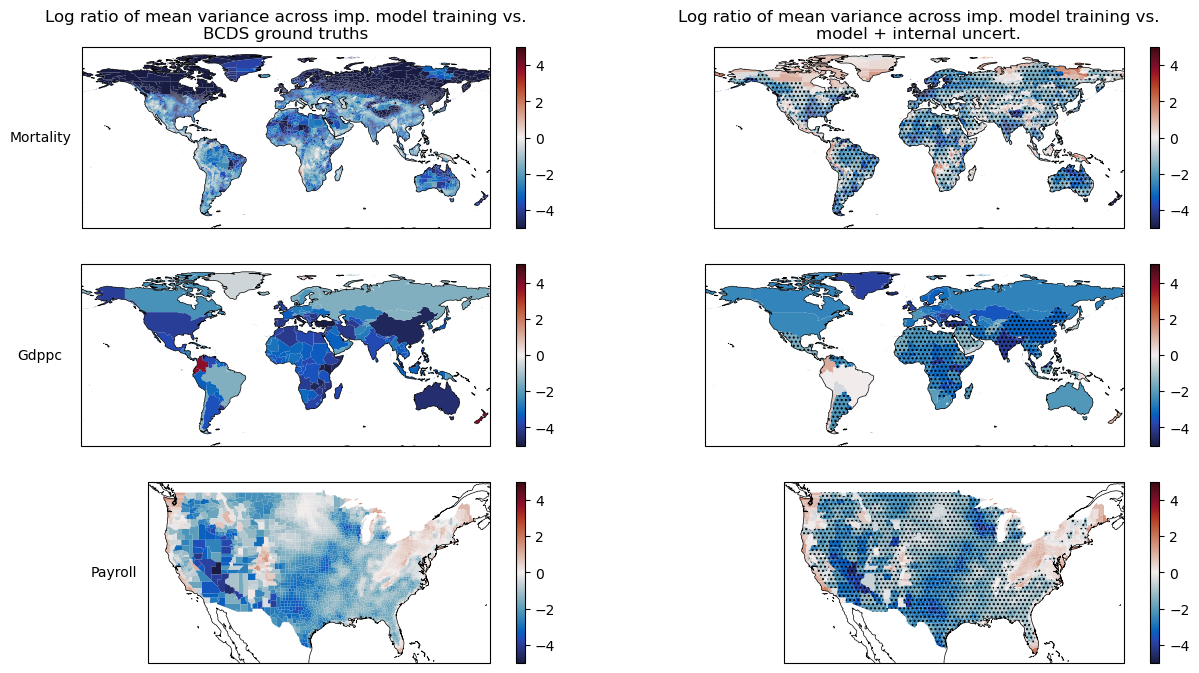

In [11]:
save_fig = True
output_fn = dir_list['figs']+'Figure4'



fig = plt.figure(figsize=(15,8))

gwl = 2

idxs = {'impact-regions':{'hierid':'locid'},
        'adm1':{'CNTRY_NAME':'locid'},
        'adm2-us':{'FIPS':'locid'}}

indflag = 'noInd'

for row_idx,proc in enumerate(params_proc):
    
    #-------------------------------
    # Load corresponding shapefile -
    #-------------------------------
    # Load shapefile
    gdf = gpd.read_file(f'{dir_list['aux']}geo_data/{params_proc[proc]['shp_fn']}.shp')
    gdf['geometry'] = gdf.make_valid()
    
    # Name merging dimension 'locid'
    gdf = gdf.rename(idxs[params_proc[proc]['geo_typ']],axis=1)
    
    # Remove locs if necessary
    if params_proc[proc]['geo_typ'] == 'impact-regions':
        # Remove Antarctica
        gdf = gdf.query('ISO != "ATA"')
    elif params_proc[proc]['geo_typ'] == 'adm1':
        gdf = gdf.query('locid != "Antarctica"')
    elif params_proc[proc]['geo_typ'] == 'adm2-us':
        # Remove Alaska and Hawaii
        gdf = gdf.iloc[[sn not in ['Alaska','Hawaii'] for sn in gdf.STATE_NAME.values]]

    if proc == 'mortality':
        df_obsuncs = obsuncs_all[proc].sel(indflag = indflag).to_dataframe().reset_index().set_index(['gwl','locid']).sort_index()
    else:
        df_obsuncs = obsuncs_all[proc].to_dataframe().reset_index().set_index(['gwl','locid']).sort_index()
        
    ratio_to_bcds = np.log(df_obsuncs.loc[gwl]['impmod'] / df_obsuncs.loc[gwl]['bcds'])
    ratio_to_bcds.name= 'impmod_to_bcds'
    ratio_to_intmod = np.log(df_obsuncs.loc[gwl]['impmod'] / (df_obsuncs.loc[gwl]['uncint'] + 
                                                                         df_obsuncs.loc[gwl]['uncmod']))
    ratio_to_intmod.name= 'impmod_to_intmod'
    
    ratios = pd.merge(ratio_to_bcds,ratio_to_intmod,left_index=True,right_index=True)
    ratios.index = ratios.index.set_names(list(idxs[params_proc[proc]['geo_typ']].values())[0])

    gdf = gdf.join(ratios,on=list(idxs[params_proc[proc]['geo_typ']].values())[0])

    # Plot of ratio of model training to BCDS
    ax = plt.subplot(3,2,2*row_idx+1,projection=ccrs.PlateCarree())
    
    gdf.plot(column='impmod_to_bcds',legend=True,cmap=cmocean.cm.balance,vmin=-5,vmax=5,
            ax=ax,transform=ccrs.PlateCarree())
    ax.coastlines(linewidth=0.5)

    if row_idx == 0:
        ax.set_title('Log ratio of mean variance across imp. model training vs.\nBCDS ground truths')
    else:
        ax.set_title('')

    ax.annotate(proc.title(),(-0.1,0.5),xycoords = 'axes fraction',ha='center',va='center')

    # Plot of ratio of model training to mod + int
    ax = plt.subplot(3,2,2*row_idx+2,projection=ccrs.PlateCarree())
    
    gdf.plot(column='impmod_to_intmod',legend=True,cmap=cmocean.cm.balance,vmin=-5,vmax=5,
            ax=ax,transform=ccrs.PlateCarree())

    # Add hatching to areas where impmod is _not_ larger than both uncint or uncmod
    imp_largest_source = (df_obsuncs['impmod'] > df_obsuncs['uncint']) & (df_obsuncs['impmod'] > df_obsuncs['uncmod'])
    gdf.set_index('locid').where(~imp_largest_source.loc[gwl]).dropna().dissolve().plot(hatch='....',facecolor='none',linewidth=0,
                                                                                        transform=ccrs.PlateCarree(),
                                                                                        ax=ax)
    
    ax.coastlines(linewidth=0.5)

    if row_idx == 0:
        ax.set_title('Log ratio of mean variance across imp. model training vs.\nmodel + internal uncert.')
    else:
        ax.set_title('')

if save_fig:
    utility_print(output_fn)
    

In [10]:
ratios.index.set_names(list(idxs[params_proc[proc]['geo_typ']].keys())[0])

Index(['ABW', 'AFG.1.12', 'AFG.1.R8abddb145b8788ee', 'AFG.1.R91a8634efe8e02a7',
       'AFG.1.Ra6a2bba0a271cb4a', 'AFG.1.Rcf29900a4c191e96',
       'AFG.1.Rd0d6327d56611fba', 'AFG.10.103', 'AFG.10.106', 'AFG.10.109',
       ...
       'ZWE.7.38', 'ZWE.7.R3a4b03768772fd50', 'ZWE.7.R3ac5f443d0b57477',
       'ZWE.8.39', 'ZWE.8.41', 'ZWE.8.43', 'ZWE.8.R463b268caaace66f',
       'ZWE.8.Raef3712f385d02bc', 'ZWE.9.46', 'ZWE.9.R19a261b63a503c9c'],
      dtype='str', name='hierid', length=24378)

In [4]:
proc = 'mortality'

tmp_fn1 = f'{dir_list['aux_bigmem']}crossfit_{proc}_rechk_tmp1.zarr'
tmp_fn2 = f'{dir_list['aux_bigmem']}crossfit_{proc}_rechk_tmp2.zarr'
if not os.path.exists(tmp_fn2):
    dss = load_impacts(proc,'allruns',return_crossfits=True)
    dss = dss.chunk({'gwl':1,'fit_mod':-1,'proj_base':-1,'locid':5000})
    # Save rechunked as temporary file
    
    utility_save(dss,tmp_fn1,zarr_mode='w')
    dss = xr.open_zarr(tmp_fn1)
    dss = dss.chunk({'gwl':1,'fit_mod':-1,'proj_base':-1,'locid':200,'exprun':-1,'model':-1})
    
    utility_save(dss.drop_encoding(),tmp_fn2,zarr_mode='w')
    os.system('rm -rf '+tmp_fn1)
dss = xr.open_zarr(tmp_fn2)

#for problem_run in problem_runs:
#    dss = dss.where(~((dss.model == problem_run['model']) & 
#            (dss.exprun == problem_run['exprun'])))

In [5]:
a = dss.sel(model='IPSL-CM6A-LR',gwl=2).dropna('exprun',how='all').load()

(array([3.300000e+01, 2.890000e+02, 1.668000e+03, 1.595300e+04,
        2.140850e+06, 8.728708e+06, 3.070600e+04, 2.564000e+03,
        1.080000e+02, 1.700000e+01]),
 array([-579.45144015, -465.49193996, -351.53243977, -237.57293958,
        -123.61343939,   -9.65393921,  104.30556098,  218.26506117,
         332.22456136,  446.18406154,  560.14356173]),
 <BarContainer object of 10 artists>)

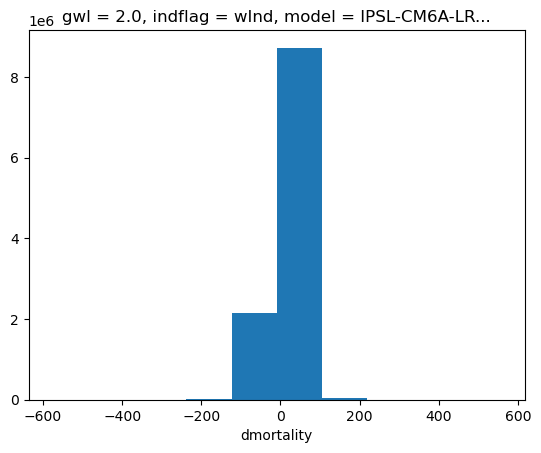

In [6]:
a.sel(indflag='wInd').dmortality.plot.hist()

In [7]:
mask = a.dmortality > 350
for dim in a.dims:
    frac_bad = mask.mean(dim=[d for d in a.dims if d != dim])
    print(f"\n--- {dim} ---")
    print(frac_bad.to_series().sort_values(ascending=False).head(10))


--- indflag ---
indflag
wInd     7.141978e-06
noInd    6.409468e-07
Name: dmortality, dtype: float64

--- fit_mod ---
fit_mod
GMFD      0.000016
ERA5      0.000000
JRA-3Q    0.000000
MERRA2    0.000000
Name: dmortality, dtype: float64

--- locid ---
locid
RUS.65.1741.1858    0.039062
RUS.65.1753.1870    0.016741
RUS.65.1728.1845    0.008929
CAN.8.117.2359      0.006696
RUS.5.108.108       0.005580
RUS.65.1727.1844    0.005580
CAN.8.119.2375      0.004464
RUS.65.1756.1873    0.004464
CAN.8.117.2355      0.002232
RUS.65.1749.1866    0.001116
Name: dmortality, dtype: float64

--- proj_base ---
proj_base
GMFD      1.355145e-05
JRA-3Q    1.281894e-06
ERA5      7.325106e-07
MERRA2    0.000000e+00
Name: dmortality, dtype: float64

--- exprun ---
exprun
ssp245r3i1p1f1     0.000013
ssp370r3i1p1f1     0.000013
ssp585r3i1p1f1     0.000010
ssp585r14i1p1f1    0.000009
ssp370r9i1p1f1     0.000008
ssp245r14i1p1f1    0.000005
ssp370r14i1p1f1    0.000005
ssp370r5i1p1f1     0.000005
ssp245r5i1p1f1     

In [69]:
np.abs(dss.sel(gwl=2).isel(indflag=0,locid=2833).dmortality.load()).max('exprun').max('fit_mod').max('proj_base')

<xarray.DataArray 'dmortality' (model: 12)> Size: 96B
array([1.35986373e+01, 1.37004198e+01, 1.66817716e+01, 1.50979498e+01,
       9.40113553e+00, 1.22999370e+01, 1.15207803e+01, 1.07082917e+01,
       6.30582654e+06, 1.35531553e+01, 1.56979489e+01, 1.11424253e+01])
Coordinates:
  * model       (model) <U13 624B 'ACCESS-ESM1-5' 'CESM2-WACCM' ... 'MRI-ESM2-0'
    gwl         float64 8B 2.0
    indflag     <U5 20B 'noInd'
    locid       <U12 48B 'NZL.5.23.153'
    obstreat    <U3 12B 'sep'
    resolution  <U6 24B '025deg'
    spec        <U6 24B 'pooled'
    timeframe   <U9 36B '1980-2010'

In [29]:
a = dss.sel(gwl=2).mean('fit_mod').std('proj_base').mean('exprun').compute()
b = dss.sel(gwl=2).std('fit_mod').mean('proj_base').mean('exprun').compute()

In [14]:
c = dss.sel(gwl=2).mean('fit_mod').mean('proj_base').std('exprun').compute()

In [30]:
a.dmortality.mean('locid')
#a.dpayroll.mean('locid')

<xarray.DataArray 'dmortality' (indflag: 2, model: 12)> Size: 192B
array([[  2.23057033,   1.97911459,   2.19604843,   2.16850985,
          1.94204675,   1.9298803 ,   1.7236583 ,   2.21174258,
         36.22903504,   2.48186369, 551.44898099,   1.99202026],
       [  2.15602646,   1.92014167,   2.13696441,   2.10448151,
          1.87659654,   1.87269408,   1.66677537,   2.14373363,
         31.92321541,   2.38855614, 483.09020482,   1.91773524]])
Coordinates:
  * indflag     (indflag) object 16B 'noInd' 'wInd'
  * model       (model) <U13 624B 'ACCESS-ESM1-5' 'CESM2-WACCM' ... 'MRI-ESM2-0'
    gwl         float64 8B 2.0
    obstreat    <U3 12B 'sep'
    resolution  <U6 24B '025deg'
    spec        <U6 24B 'pooled'
    timeframe   <U9 36B '1980-2010'

In [164]:
a.dmortality.mean('locid')/b.dmortality.mean('locid')

<xarray.DataArray 'dmortality' (model: 12)> Size: 96B
array([0.2775066 , 0.27768754, 0.28457467, 0.27899785, 0.27884213,
       0.3010339 , 0.26925632, 0.27877241, 1.94036876, 0.30850454,
       2.87578763, 0.27759269])
Coordinates:
  * model       (model) <U13 624B 'ACCESS-ESM1-5' 'CESM2-WACCM' ... 'MRI-ESM2-0'
    gwl         float64 8B 2.0
    indflag     <U5 20B 'noInd'
    obstreat    <U3 12B 'sep'
    resolution  <U6 24B '025deg'
    spec        <U6 24B 'pooled'
    timeframe   <U9 36B '1980-2010'

In [201]:
np.where((a.experiment.values == 'ssp370') & (a.run.values == 'r6i1p1f1'))[0]

array([18])

In [206]:
a = xr.open_zarr('/glade/campaign/cgd/cas/schwarzwald/bcd_me/bcd_me_qdm-qplad_IPSL-CM6A-LR.zarr',decode_timedelta=False)
a1 = a.isel(idv=18).tassumpoly.sel(gwl=2,degree=1).load()
a0 = a.isel(idv=17).tassumpoly.sel(gwl=2,degree=1).load()

(array([  8885.,  19350.,  53364., 125581., 132291., 139661., 117652.,
        116966., 268345.,  67417.]),
 array([-10856.49316406,  -8495.3046875 ,  -6134.11572266,  -3772.92675781,
         -1411.73828125,    949.45019531,   3310.63964844,   5671.82714844,
          8033.01660156,  10394.20605469,  12755.39257812]),
 <BarContainer object of 10 artists>)

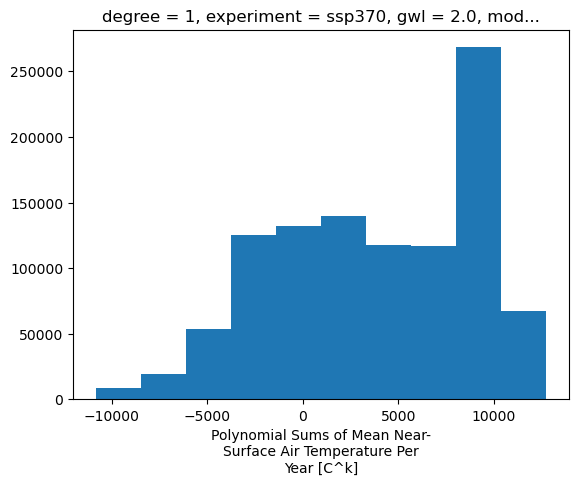

In [209]:
a0.plot()

In [ ]:
## PROBLEMS, HAVE TO TAKE OUT OF BCD-ME, 
## NO CLUE WHY IT DIDN'T SHOW UP ON TECHNICAL CHECKS
('IPSL-CM6A-LR','ssp370','r6i1p1f1')
('MPI-ESM1-2-LR','ssp370','r9i1p1f1')

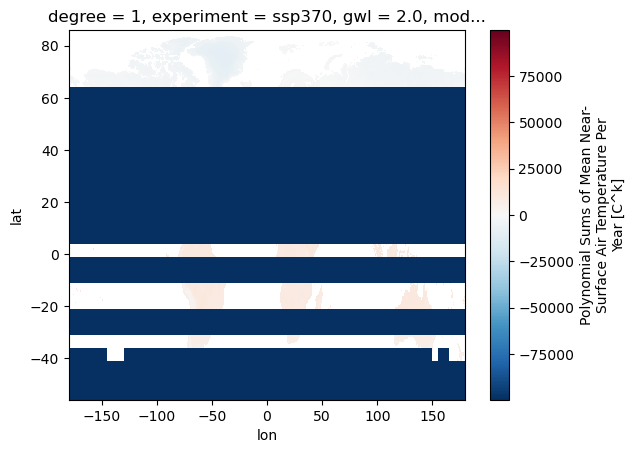

In [215]:
a1.isel(proj_base=3).plot()

In [193]:
dss.isel(model=10,gwl=3).mean('fit_mod').mean('proj_base').dmortality.mean('locid').dropna('exprun').compute().isel(exprun=19)

<xarray.DataArray 'dmortality' ()> Size: 8B
array(9522.08786944)
Coordinates:
    experiment  <U6 24B 'ssp370'
    exprun      <U20 80B 'ssp370r9i1p1f1'
    gwl         float64 8B 2.0
    indflag     <U5 20B 'noInd'
    maxgwl      float64 8B 2.5
    model       <U13 52B 'MPI-ESM1-2-LR'
    obstreat    <U3 12B 'sep'
    resolution  <U6 24B '025deg'
    run         <U9 36B 'r9i1p1f1'
    spec        <U6 24B 'pooled'
    timeframe   <U9 36B '1980-2010'

In [174]:
dss.model.values[8]

np.str_('IPSL-CM6A-LR')

In [169]:
c.mean('locid').dmortality

<xarray.DataArray 'dmortality' (model: 12)> Size: 96B
array([   2.94837703,    2.03827925,    2.65719027,    3.23577766,
          2.47519208,    3.3115351 ,    3.05124185,    2.20418883,
        104.48363606,    3.99321678, 1710.96651719,    2.47385145])
Coordinates:
  * model       (model) <U13 624B 'ACCESS-ESM1-5' 'CESM2-WACCM' ... 'MRI-ESM2-0'
    gwl         float64 8B 2.0
    indflag     <U5 20B 'noInd'
    obstreat    <U3 12B 'sep'
    resolution  <U6 24B '025deg'
    spec        <U6 24B 'pooled'
    timeframe   <U9 36B '1980-2010'

In [173]:
a.mean('locid').dmortality

<xarray.DataArray 'dmortality' (model: 12)> Size: 96B
array([  2.23057033,   1.97911459,   2.19604843,   2.16850985,
         1.94204675,   1.9298803 ,   1.7236583 ,   2.21174258,
        36.22903504,   2.48186369, 551.44898099,   1.99202026])
Coordinates:
  * model       (model) <U13 624B 'ACCESS-ESM1-5' 'CESM2-WACCM' ... 'MRI-ESM2-0'
    gwl         float64 8B 2.0
    indflag     <U5 20B 'noInd'
    obstreat    <U3 12B 'sep'
    resolution  <U6 24B '025deg'
    spec        <U6 24B 'pooled'
    timeframe   <U9 36B '1980-2010'

<Axes: xlabel='impmod', ylabel='bcds'>

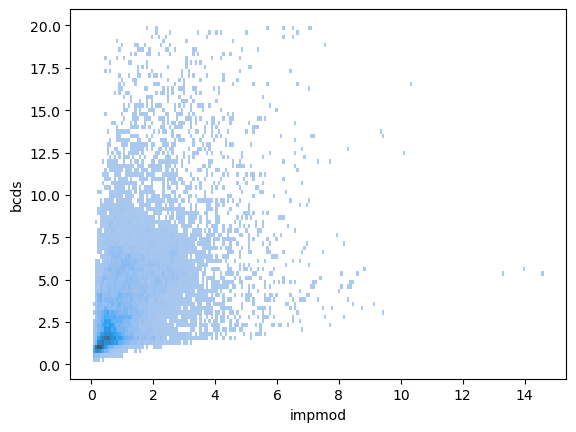

In [17]:
sns.histplot(data = df_obsuncs.where(df_obsuncs < 20).dropna().loc[1.5],
             x='impmod',
             y='bcds')


<Axes: xlabel='impmod', ylabel='bcds'>

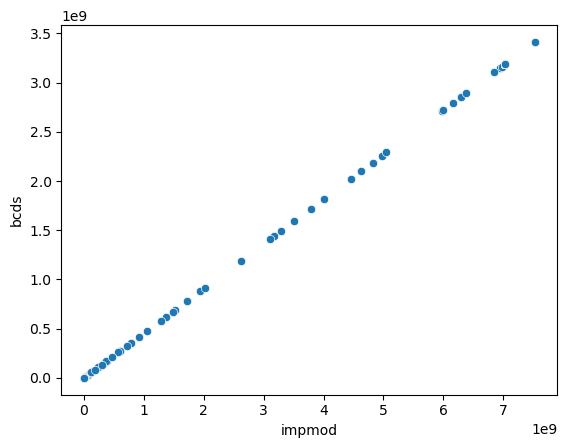

In [44]:
sns.scatterplot(data= df_obsuncs.loc[2],
            x = 'impmod',
            y = 'bcds')

In [29]:
sns.df_obsuncs.loc[2]

,impmod,bcds
locid,,
ABW,84.979579,6.449844
AFG.1.12,395.045540,71.870644
AFG.1.R8abddb145b8788ee,29.258609,5.108814
AFG.1.R91a8634efe8e02a7,35.126557,2.496250
AFG.1.Ra6a2bba0a271cb4a,6.238896,4.284145
...,...,...
ZWE.8.43,33.643258,3.054785
ZWE.8.R463b268caaace66f,51.009167,10.211370
ZWE.8.Raef3712f385d02bc,28.648275,2.142084
